<a href="https://colab.research.google.com/github/wan-chtvlv/spatial-coastal-ses/blob/main/Coastal_waste_dynamic_map.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
from pathlib import Path

if Path('/content/drive/MyDrive/').exists():
    print("Google Drive is connected")
else:
    drive.mount('/content/drive')
    print("Successfully connect to Google Drive")

print("MyDrive exists:", Path('/content/drive/MyDrive').exists())

Mounted at /content/drive
Successfully connect to Google Drive
MyDrive exists: True


In [ ]:
from pathlib import Path

PROJECT_DIR = Path('/content/drive/MyDrive/Coastal_Waste_Dynamics')
INPUT_DIR = PROJECT_DIR / 'input'
OUTPUT_DIR = PROJECT_DIR / 'output'

INPUT_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [ ]:
# Libraries imports
# ------------------------------------------
!sudo apt-get install swig
!pip install s2geometry geopandas

import functools
import glob
import gzip
import multiprocessing
import os
import shutil
import tempfile
from typing import List, Optional, Tuple

import geopandas as gpd
from IPython import display
import pandas as pd
import s2geometry as s2
import shapely
import tensorflow as tf
import tqdm.notebook
# ------------------------------------------

Google Open Building

HydroRIVERS

HydroBASINS

output: Alterlife of rivers (compare with Meijer et al, 2021)

In [ ]:
# Libraries imports
# ------------------------------------------
!pip install copernicusmarine

import copernicusmarine
import xarray as xr

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.2/16.2 MB 56.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 58.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35/35 [copernicusmarine]


In [ ]:
# Understanding the package
# Tutorial and documentation: https://help.marine.copernicus.eu/en/articles/8283072-copernicus-marine-toolbox-api-subset
# call documentation
?copernicusmarine.subset

In [ ]:
copernicusmarine.subset(
  dataset_id="cmems_mod_glo_phy-cur_anfc_0.083deg_P1M-m",
  variables=["uo", "vo"],
  minimum_longitude=93,
  maximum_longitude=130,
  minimum_latitude=-12,
  maximum_latitude=20,
  start_datetime="2025-01-01T00:00:00",
  end_datetime="2025-12-31T23:59:00",
  minimum_depth=0,
  maximum_depth=30,
  output_filename = "SEA_ocean_monthly_velocity.nc",
  output_directory = INPUT_DIR
)


INFO - 2026-10-30T00:18:06Z - Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register
INFO:copernicusmarine:Downloading Copernicus Marine data requires a Copernicus Marine username and password, sign up for free at: https://data.marine.copernicus.eu/register


Copernicus Marine username: wan.c.c@rutgers.edu
Copernicus Marine password: ··········


INFO - 2026-10-30T00:18:47Z - Selected dataset version: "202406"
INFO:copernicusmarine:Selected dataset version: "202406"
INFO - 2026-10-30T00:18:47Z - Selected dataset part: "default"
INFO:copernicusmarine:Selected dataset part: "default"
WARNING - 2026-10-30T00:18:47Z - Some of your subset selection [0.0, 30.0] for the depth dimension exceed the dataset coordinates [0.49402499198913574, 5727.9169921875]


  0%|          | [00:00<?]

INFO - 2026-10-30T00:19:41Z - Total size of the download: 235.43 MB.
INFO:copernicusmarine:Total size of the download: 235.43 MB.


ResponseSubset(file_path=PosixPath('/content/drive/MyDrive/Coastal_Waste_Dynamics/input/SEA_ocean_monthly_velocity.nc'), output_directory=PosixPath('/content/drive/MyDrive/Coastal_Waste_Dynamics/input'), filename='SEA_ocean_monthly_velocity.nc', file_size=235.42793893129772, data_transfer_size=720.3957251908397, variables=['uo', 'vo'], coordinates_extent=[GeographicalExtent(minimum=93.0, maximum=130.0, unit='degrees_east', coordinate_id='longitude'), GeographicalExtent(minimum=-12.0, maximum=20.0, unit='degrees_north', coordinate_id='latitude'), TimeExtent(minimum='2025-01-01T00:00:00+00:00', maximum='2025-12-01T00:00:00+00:00', unit='iso8601', coordinate_id='time'), GeographicalExtent(minimum=0.49402499198913574, maximum=29.444730758666992, unit='m', coordinate_id='depth')], status='000', message='The request was successful.', file_status='DOWNLOADED', file_names=None)

In [ ]:
# Following, how to plot current vectors with Python.
# https://help.marine.copernicus.eu/en/articles/7044577-how-to-plot-current-vectors-with-python
!pip install cartopy

import xarray as xr
import matplotlib.pyplot as plt
import numpy as np

import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Open dataset
ocean = xr.open_dataset(INPUT_DIR / 'SEA_ocean_monthly_velocity.nc')
ocean

<xarray.Dataset> Size: 247MB
Dimensions:    (time: 12, depth: 15, latitude: 385, longitude: 445)
Coordinates:
  * time       (time) datetime64[ns] 96B 2025-01-01 2025-02-01 ... 2025-12-01
  * depth      (depth) float32 60B 0.494 1.541 2.646 3.819 ... 21.6 25.21 29.44
  * latitude   (latitude) float32 2kB -12.0 -11.92 -11.83 ... 19.83 19.92 20.0
  * longitude  (longitude) float32 2kB 93.0 93.08 93.17 ... 129.8 129.9 130.0
Data variables:
    uo         (time, depth, latitude, longitude) float32 123MB ...
    vo         (time, depth, latitude, longitude) float32 123MB ...
Attributes: (12/14)
    Conventions:                   CF-1.6
    area:                          GLOBAL
    contact:                       servicedesk.cmems@mercator-ocean.eu
    credit:                        E.U. Copernicus Marine Service Information...
    institution:                   Mercator Ocean
    licence:                       http://marine.copernicus.eu/services-portf...
    ...                            ...
    product_user_manual:           http://marine.copernicus.eu/documents/PUM/...
    quality_information_document:  http://marine.copernicus.eu/documents/QUID...
    references:                    http://marine.copernicus.eu
    source:                        MERCATOR GLO12
    title:                         Monthly mean fields for product GLOBAL_ANA...
    copernicusmarine_version:      2.5.0

In [ ]:
def SEA_ocean_plot (target_time, data, depth_velocity):
  selected_data = data.sel(
      time=target_time,
      method="nearest"
      )

  if "depth" in selected_data.dims:
      selected_data = selected_data.sel(
          depth = depth_velocity,
          method = "nearest",
      )
  u = selected_data["uo"].transpose("latitude", "longitude")
  v = selected_data["vo"].transpose("latitude", "longitude")
  current_speed = np.hypot(u, v)

  # Figure settings
  width_inch = 15
  height_inch = 10

  # Vector display settings
  arrow_step = 5
  quiver_scale = 20

  # Create the map
  fig, ax = plt.subplots(
      figsize=(width_inch, height_inch),
      subplot_kw={"projection": ccrs.PlateCarree()},
  )

  longitude = selected_data["longitude"].values
  latitude = selected_data["latitude"].values

  # Display current speed as a background field
  mesh = ax.pcolormesh(
      longitude,
      latitude,
      current_speed,
      cmap="Blues",
      shading="auto",
      transform=ccrs.PlateCarree(),
  )

  # Reduce arrow density for readability
  skip = (
      slice(None, None, arrow_step),
      slice(None, None, arrow_step),
  )

  # Display current vectors
  quiver = ax.quiver(
      longitude[::arrow_step],
      latitude[::arrow_step],
      u.values[skip],
      v.values[skip],
      color="black",
      scale=quiver_scale,
      width=0.001,
      headwidth=5,
      transform=ccrs.PlateCarree(),
  )

  # Add geographical information
  ax.coastlines()
  ax.add_feature(
      cfeature.BORDERS,
      linestyle=":",
  )

  gridlines = ax.gridlines(
      draw_labels=True,
      linewidth=0.5,
      color="gray",
      alpha=0.5,
      linestyle="dotted",
  )
  gridlines.top_labels = False
  gridlines.right_labels = False

  # Add the color bar
  colorbar = plt.colorbar(
      mesh,
      ax=ax,
      orientation="horizontal",
      pad=0.1,
      shrink=0.6,
  )
  colorbar.set_label("Current speed [m/s]")

  # Add a reference vector
  ax.quiverkey(
      quiver,
      X=0.9,
      Y=-0.08,
      U=1,
      label="1 m/s",
      labelpos="E",
      coordinates="axes",
  )

  ax.set_title("Monthly average current speed and direction at " + str(depth_velocity) + "m-depth in " + target_time[:7])
  plt.savefig(str(OUTPUT_DIR) + '/ocean_vdir_' + target_time[:7] + '_' + str(depth_velocity)+'m.png', dpi=300, bbox_inches='tight')
  plt.show()


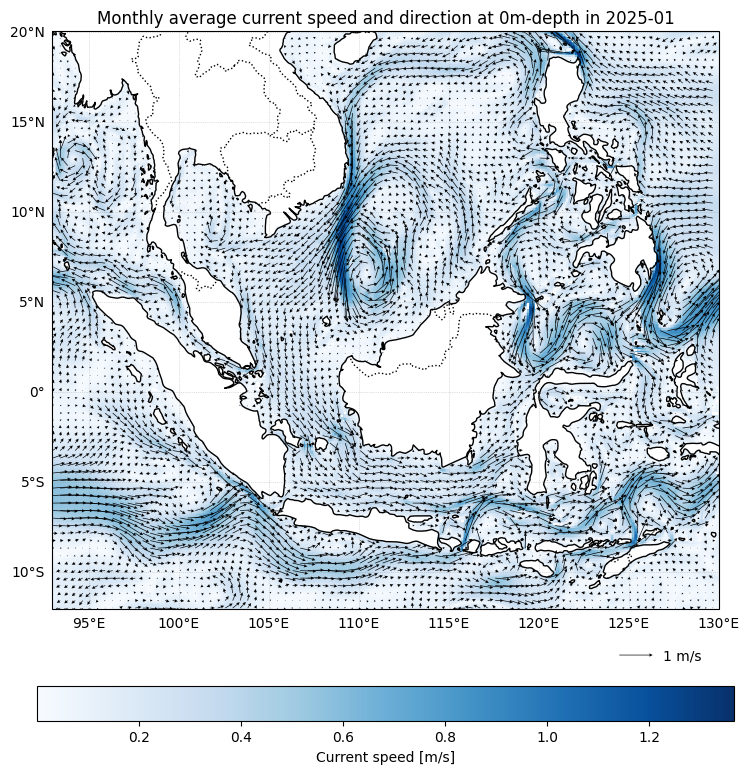

In [ ]:
month = "2025-01-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

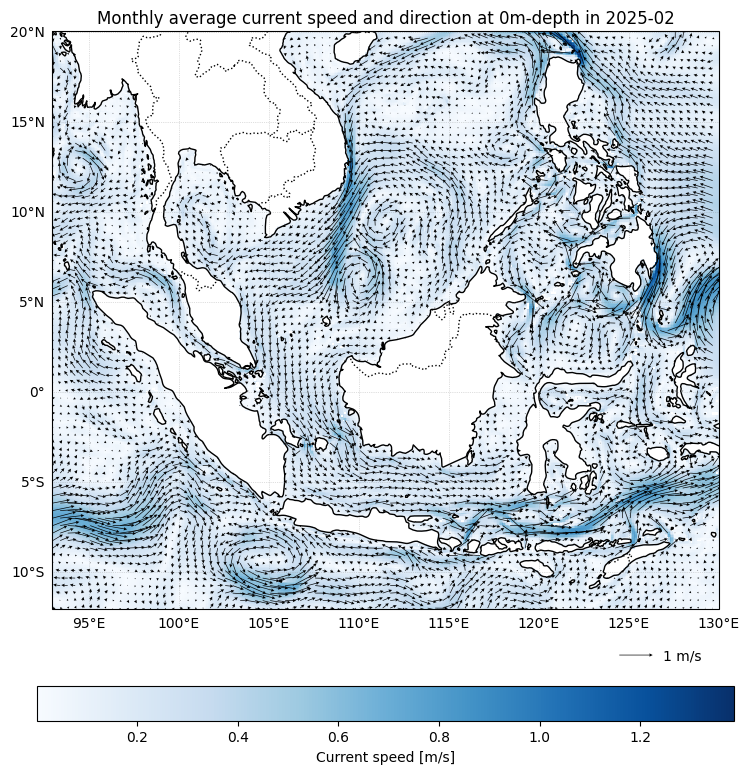

In [ ]:
month = "2025-02-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

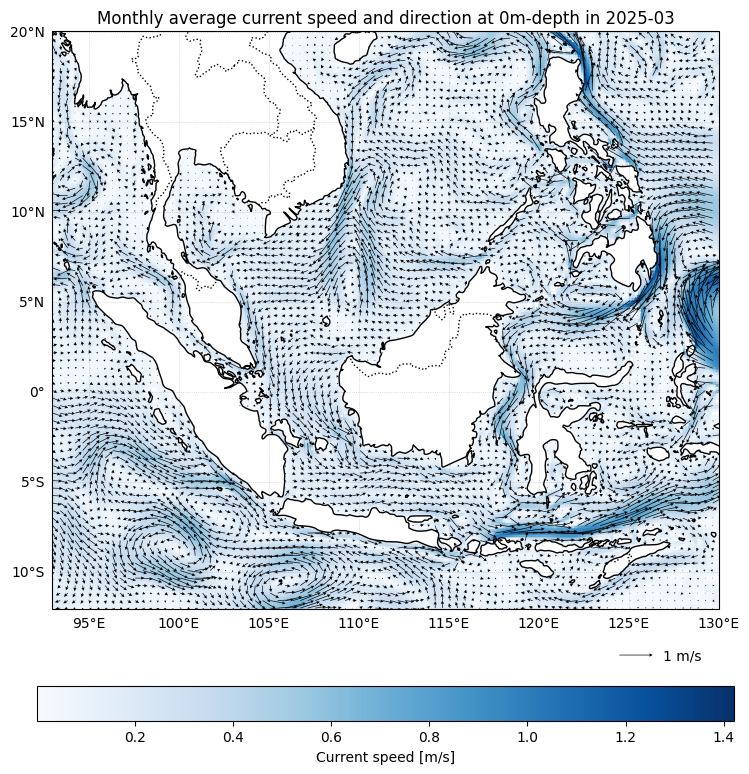

In [ ]:
month = "2025-03-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

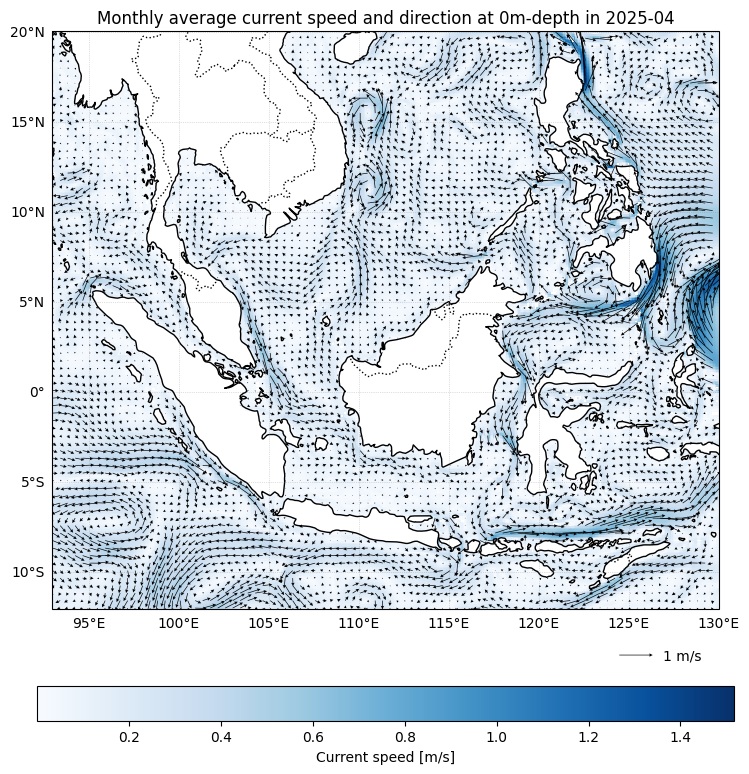

In [ ]:
month = "2025-04-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

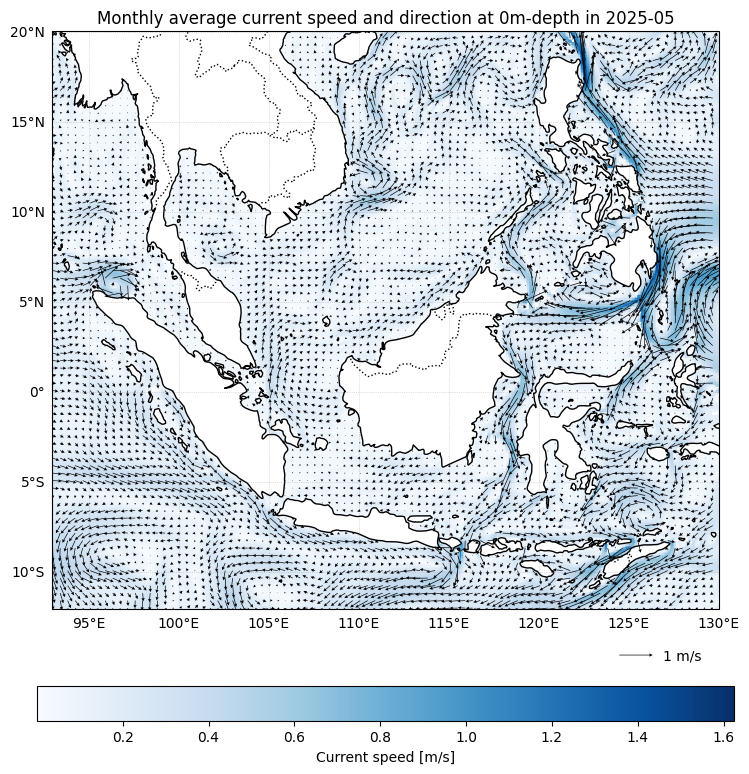

In [ ]:
month = "2025-05-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

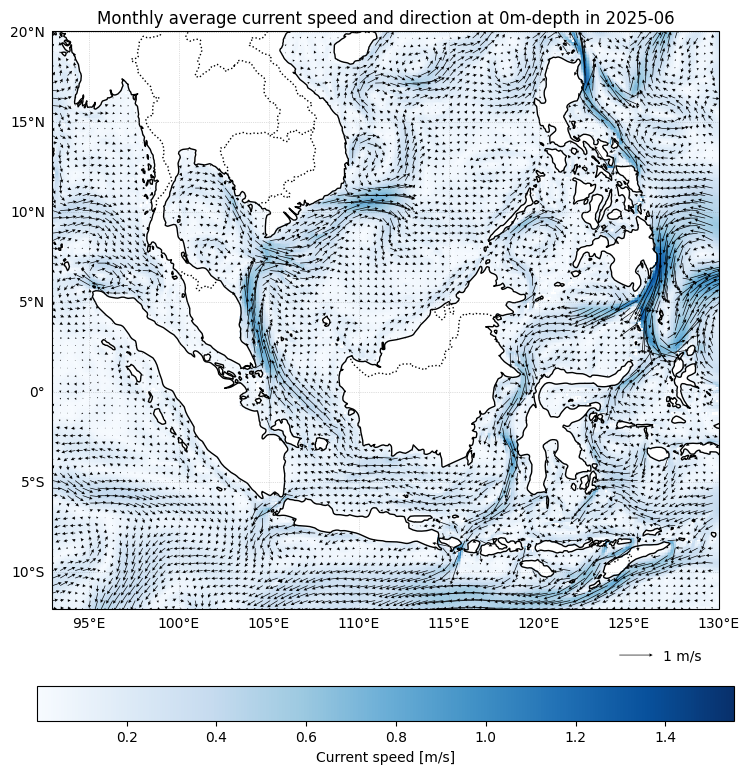

In [ ]:
month = "2025-06-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

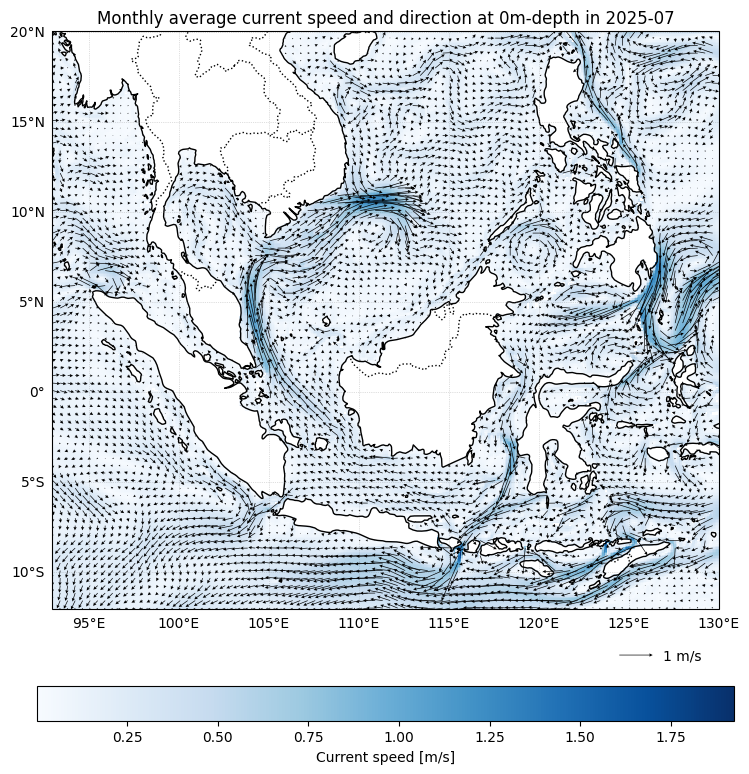

In [ ]:
month = "2025-07-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

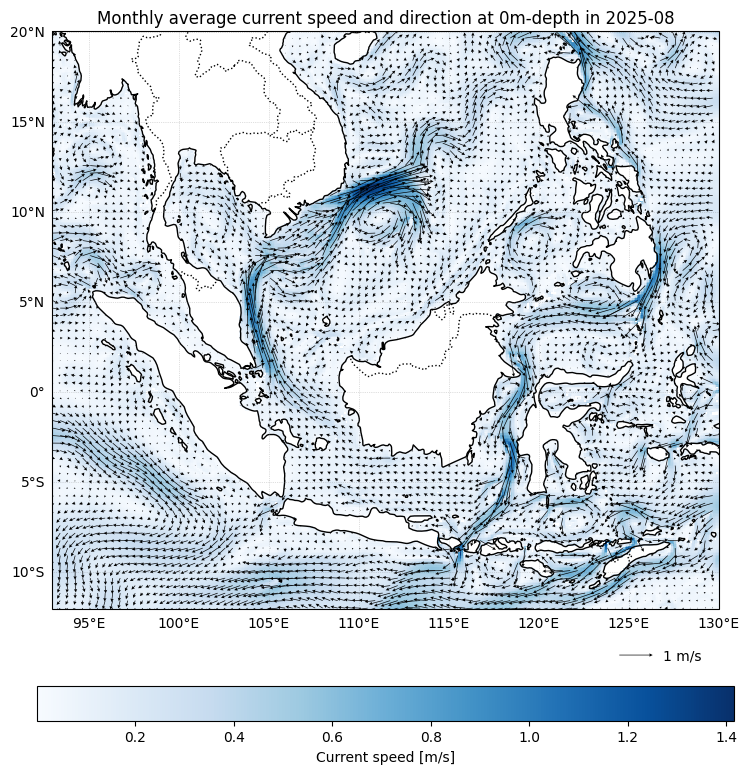

In [ ]:
month = "2025-08-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

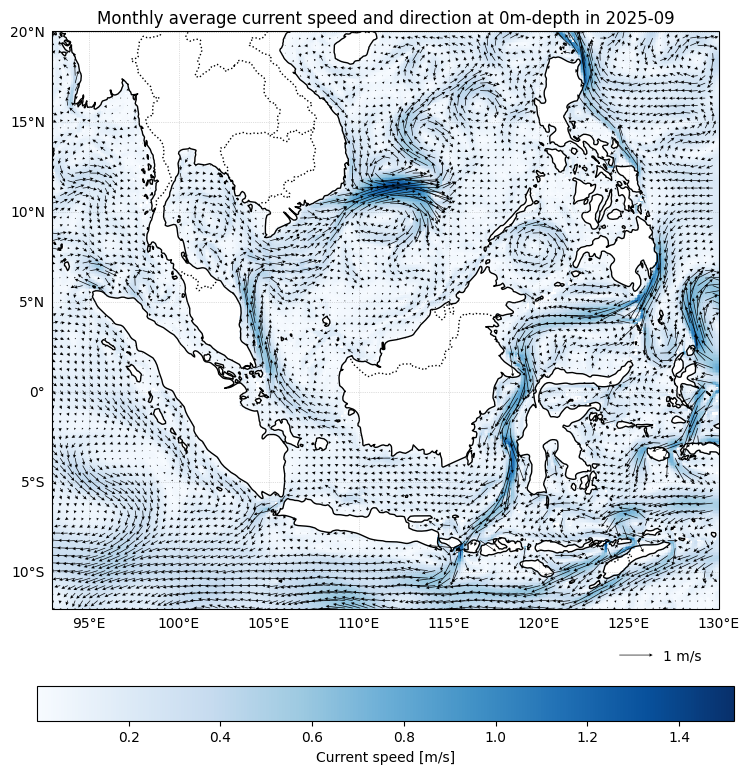

In [ ]:
month = "2025-09-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

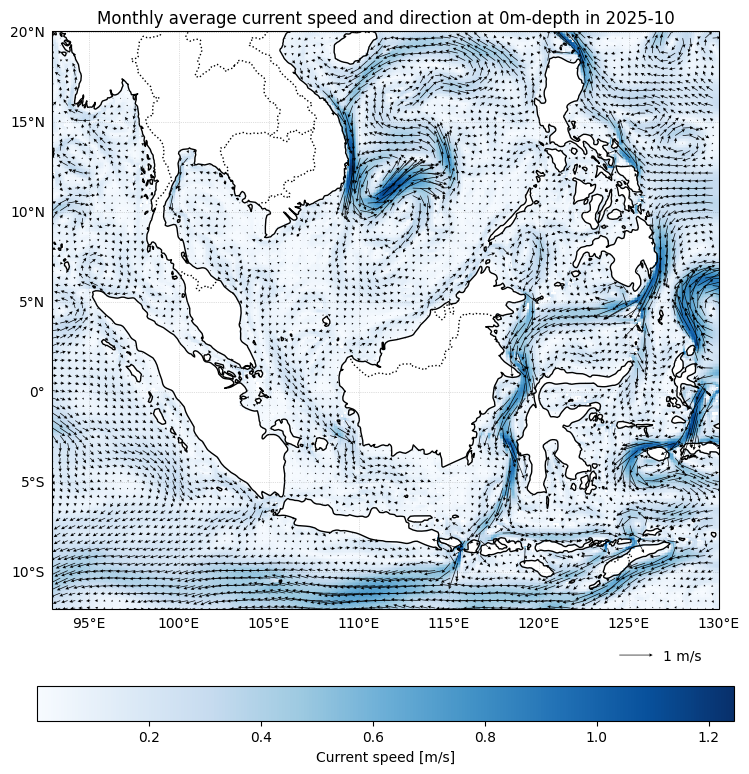

In [ ]:
month = "2025-10-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

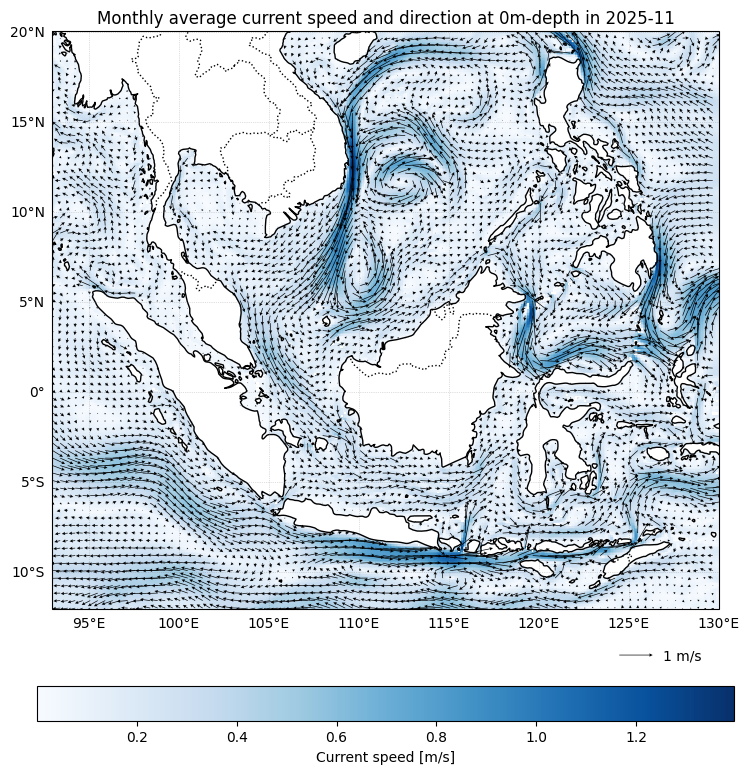

In [ ]:
month = "2025-11-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

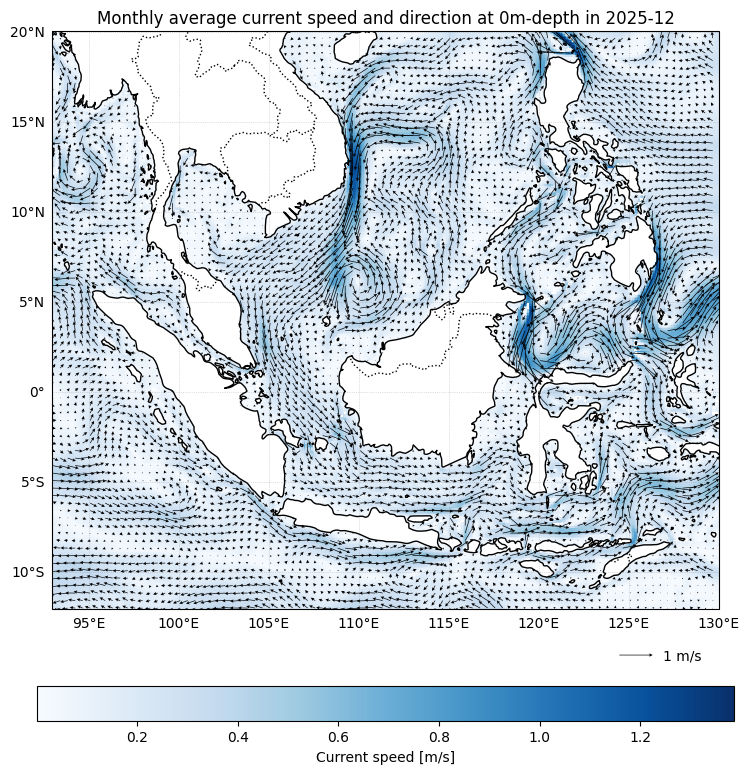

In [ ]:
month = "2025-12-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

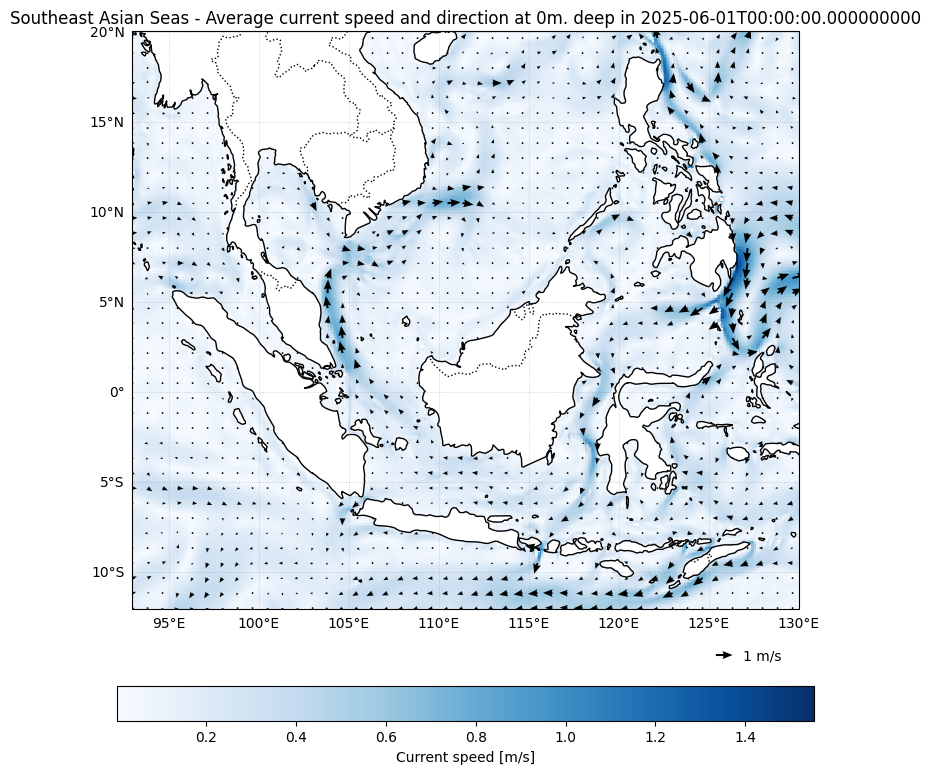

In [ ]:
month = "2025-06-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=0)

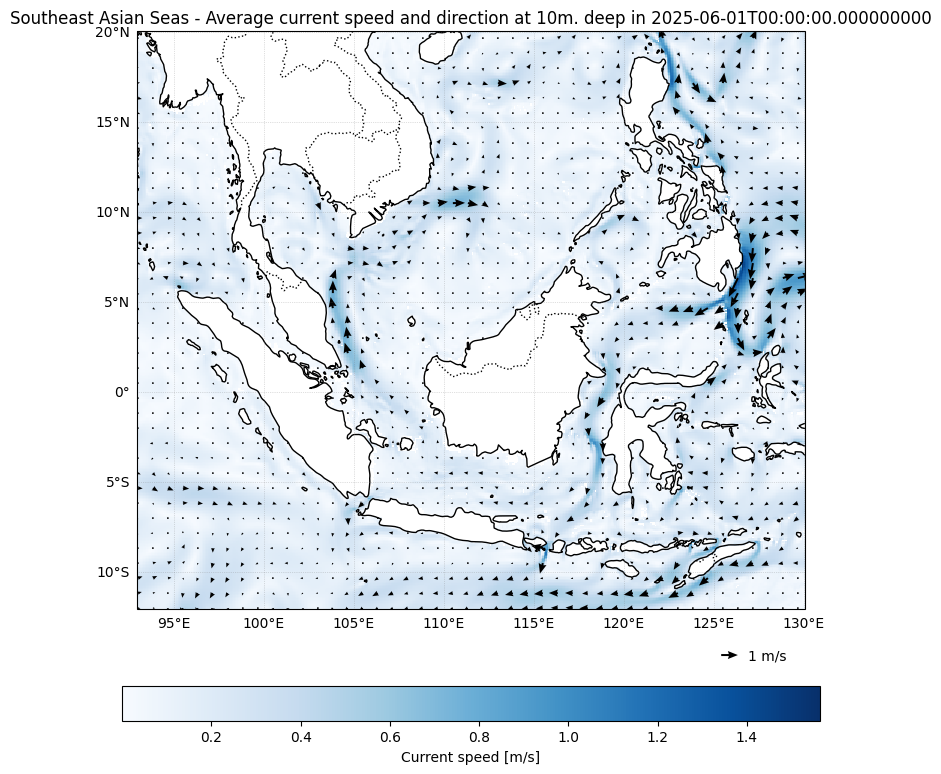

In [ ]:
month = "2025-06-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=10)

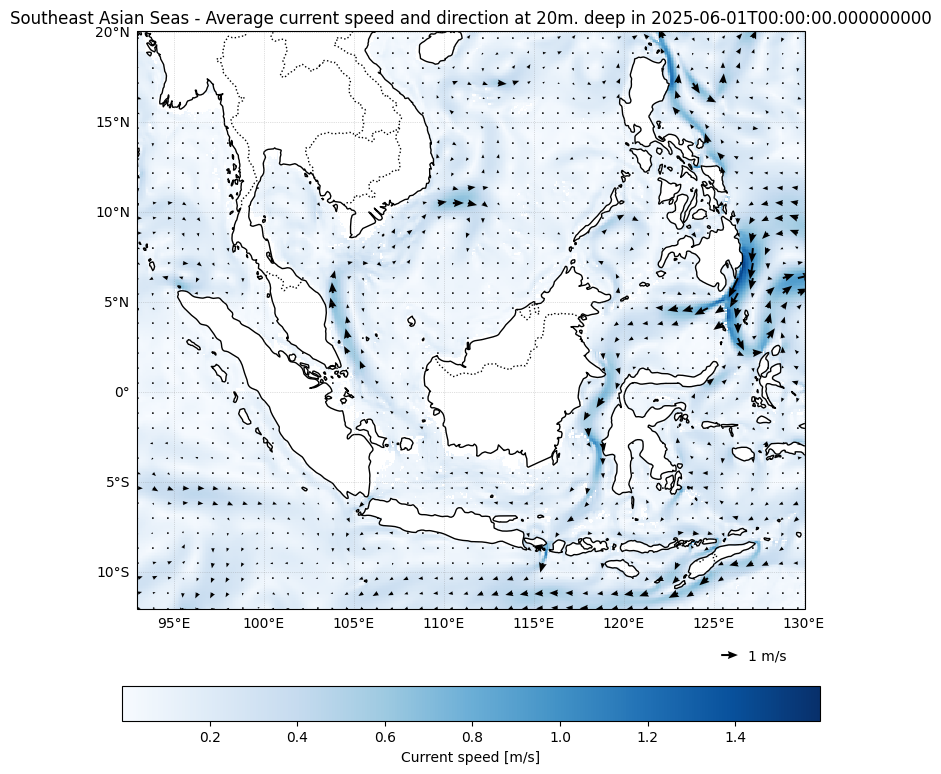

In [ ]:
month = "2025-06-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=20)

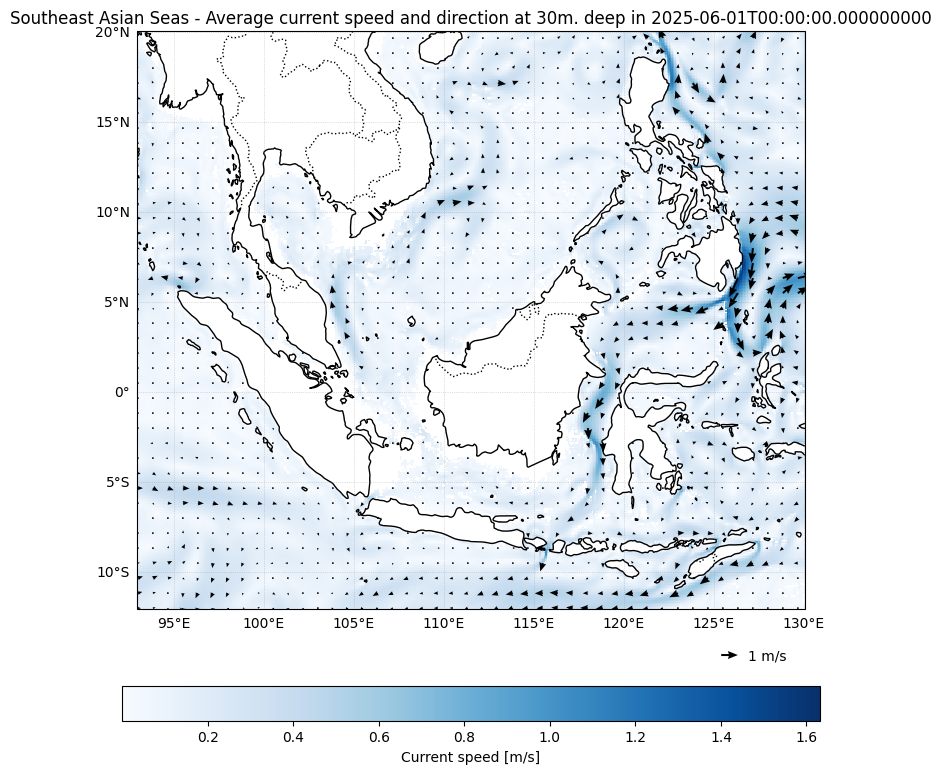

In [ ]:
month = "2025-06-01T00:00:00.000000000"
SEA_ocean_plot(target_time=month, data=ocean, depth_velocity=30)